AirPassengers Dataset Loaded
First Five Observations:


1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64

Last Five Observations:


1960-08-01    606
1960-09-01    508
1960-10-01    461
1960-11-01    390
1960-12-01    432
Freq: MS, Name: Passengers, dtype: int64

Starting Period: 1949-01-01 00:00:00
Ending Period: 1960-12-01 00:00:00
Number of Observations: 144
Frequency: 12 observations per year
Data Type: <class 'pandas.Series'>
Index Frequency: <MonthBegin>


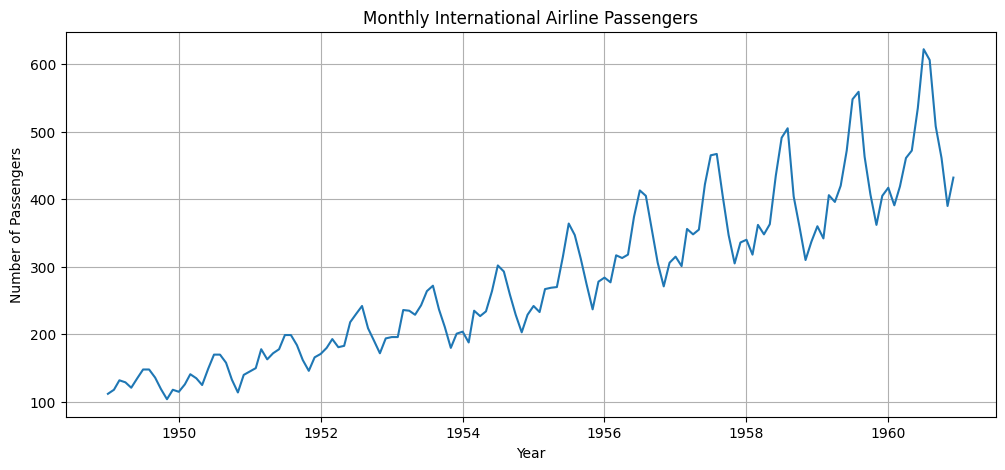

Time Series Decomposition Completed


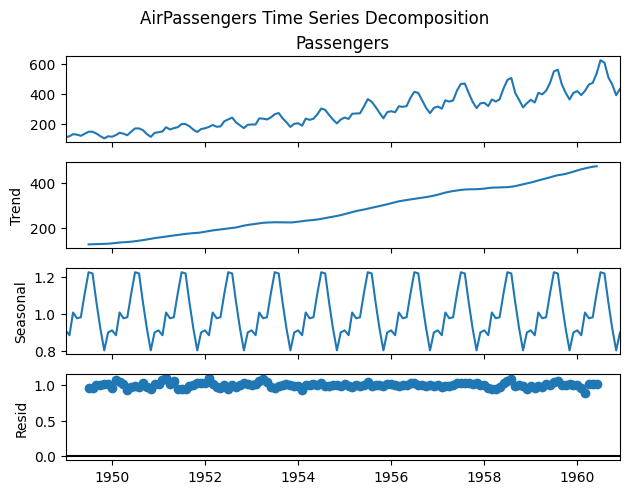

Trend:


1949-07-01    126.791667
1949-08-01    127.250000
1949-09-01    127.958333
1949-10-01    128.583333
1949-11-01    129.000000
Freq: MS, Name: trend, dtype: float64

Seasonal Component:


1949-01-01    0.910230
1949-02-01    0.883625
1949-03-01    1.007366
1949-04-01    0.975906
1949-05-01    0.981378
Freq: MS, Name: seasonal, dtype: float64

Residual Component:


1949-07-01    0.951664
1949-08-01    0.953401
1949-09-01    1.002220
1949-10-01    1.004028
1949-11-01    1.006270
Freq: MS, Name: resid, dtype: float64

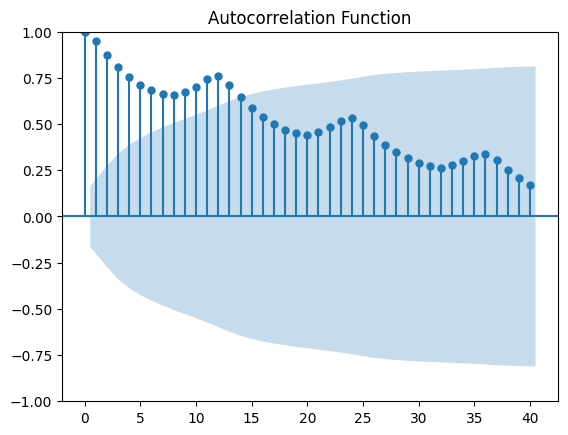

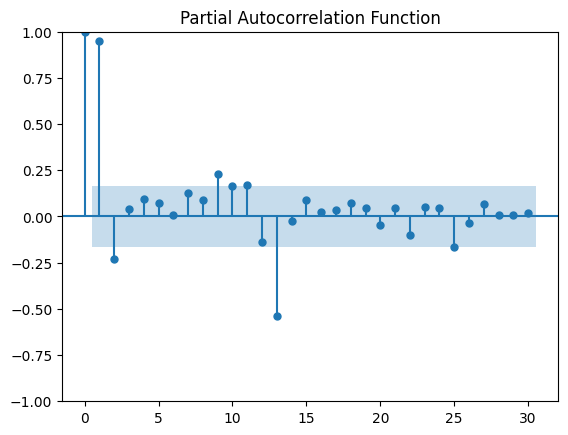

ARIMA Model Fitted Successfully
                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  144
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -694.341
Date:                Thu, 15 Oct 2026   AIC                           1394.683
Time:                        17:57:14   BIC                           1403.571
Sample:                    01-01-1949   HQIC                          1398.294
                         - 12-01-1960                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4742      0.123     -3.847      0.000      -0.716      -0.233
ma.L1          0.8635      0.078     11.051      0.000       0.710       1.017
sigma2       961.927

1961-01-01    475.735059
1961-02-01    454.996073
1961-03-01    464.830415
1961-04-01    460.167010
1961-05-01    462.378378
1961-06-01    461.329756
1961-07-01    461.827008
1961-08-01    461.591213
1961-09-01    461.703026
1961-10-01    461.650005
1961-11-01    461.675148
1961-12-01    461.663225
Freq: MS, Name: predicted_mean, dtype: float64

Confidence Intervals:


,lower Passengers,upper Passengers
1961-01-01,414.946878,536.523239
1961-02-01,350.940701,559.051444
1961-03-01,337.589154,592.071676
1961-04-01,310.631570,609.702450
1961-05-01,294.624710,630.132045
1961-06-01,276.654047,646.005465
1961-07-01,261.872945,661.781071
1961-08-01,247.349619,675.832808
1961-09-01,234.111987,689.294065
1961-10-01,221.430943,701.869067


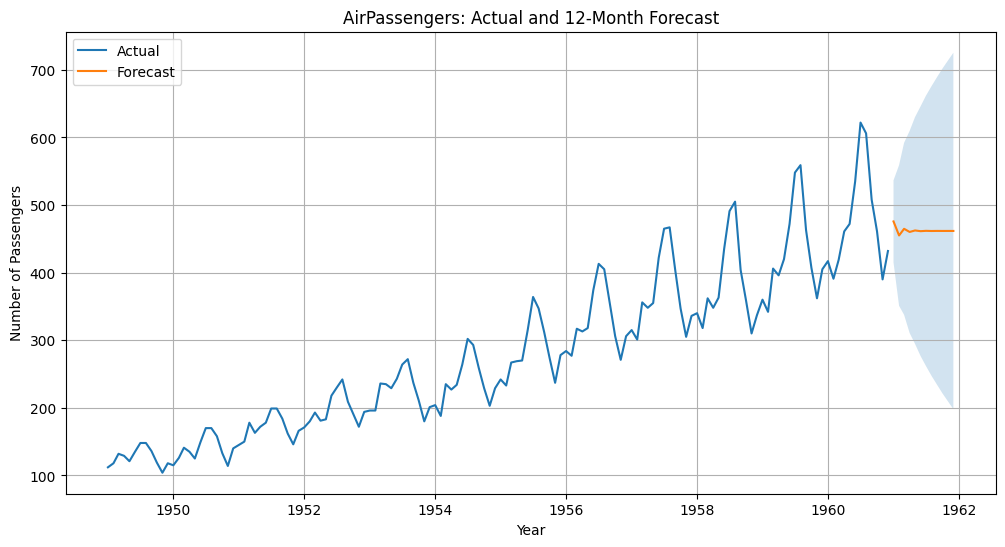

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.arima.model import ARIMA

# ASSESSMENT 6
# TIME SERIES ANALYSIS

# 1. Load AirPassengers Dataset
passengers = [
    112,118,132,129,121,135,148,148,136,119,104,118,
    115,126,141,135,125,149,170,170,158,133,114,140,
    145,150,178,163,172,178,199,199,184,162,146,166,
    171,180,193,181,183,218,230,242,209,191,172,194,
    196,196,236,235,229,243,264,272,237,211,180,201,
    204,188,235,227,234,264,302,293,259,229,203,229,
    242,233,267,269,270,315,364,347,312,274,237,278,
    284,277,317,313,318,374,413,405,355,306,271,306,
    315,301,356,348,355,422,465,467,404,347,305,336,
    340,318,362,348,363,435,491,505,404,359,310,337,
    360,342,406,396,420,472,548,559,463,407,362,405,
    417,391,419,461,472,535,622,606,508,461,390,432
]

dates = pd.date_range(
    start="1949-01-01",
    periods=len(passengers),
    freq="MS"
)

air = pd.Series(
    passengers,
    index=dates,
    name="Passengers"
)

print("AirPassengers Dataset Loaded")

# 2. First Five and Last Five Observations
print("First Five Observations:")
display(air.head())

print("Last Five Observations:")
display(air.tail())

# 3. Starting and Ending Time Period
print(
    "Starting Period:",
    air.index.min()
)

print(
    "Ending Period:",
    air.index.max()
)

# 4. Frequency and Time Series Characteristics
print(
    "Number of Observations:",
    len(air)
)

print(
    "Frequency: 12 observations per year"
)

print(
    "Data Type:",
    type(air)
)

print(
    "Index Frequency:",
    air.index.freq
)

# 5. Visualize Monthly Passenger Trend
plt.figure(figsize=(12, 5))

plt.plot(
    air.index,
    air.values
)

plt.title(
    "Monthly International Airline Passengers"
)

plt.xlabel("Year")
plt.ylabel("Number of Passengers")

plt.grid(True)

plt.show()

# 6. Decompose Time Series
decomposition = seasonal_decompose(
    air,
    model="multiplicative",
    period=12
)

print(
    "Time Series Decomposition Completed"
)

# 7. Plot Decomposed Components
decomposition.plot()

plt.suptitle(
    "AirPassengers Time Series Decomposition",
    y=1.02
)

plt.show()

# Display individual components
print("Trend:")
display(
    decomposition.trend.dropna().head()
)

print("Seasonal Component:")
display(
    decomposition.seasonal.head()
)

print("Residual Component:")
display(
    decomposition.resid.dropna().head()
)

# 8. ACF
plot_acf(
    air,
    lags=40
)

plt.title(
    "Autocorrelation Function"
)

plt.show()

# PACF
plot_pacf(
    air,
    lags=30,
    method="ywm"
)

plt.title(
    "Partial Autocorrelation Function"
)

plt.show()

# 9. Fit ARIMA Model
model = ARIMA(
    air,
    order=(1, 1, 1)
)

fitted_model = model.fit()

print(
    "ARIMA Model Fitted Successfully"
)

# 10. Display Model Summary
print(
    fitted_model.summary()
)

print(
    "AR Parameters:",
    fitted_model.arparams
)

print(
    "MA Parameters:",
    fitted_model.maparams
)

# 11. Forecast Next 12 Months
forecast_result = fitted_model.get_forecast(
    steps=12
)

forecast = forecast_result.predicted_mean

confidence_interval = (
    forecast_result.conf_int()
)

print(
    "Forecast for Next 12 Months:"
)

display(forecast)

print(
    "Confidence Intervals:"
)

display(confidence_interval)

# 12. Actual and Forecasted Passenger Values
plt.figure(figsize=(12, 6))

plt.plot(
    air.index,
    air.values,
    label="Actual"
)

plt.plot(
    forecast.index,
    forecast.values,
    label="Forecast"
)

plt.fill_between(
    confidence_interval.index,
    confidence_interval.iloc[:, 0],
    confidence_interval.iloc[:, 1],
    alpha=0.2
)

plt.title(
    "AirPassengers: Actual and 12-Month Forecast"
)

plt.xlabel("Year")
plt.ylabel("Number of Passengers")

plt.legend()
plt.grid(True)

plt.show()